# Incremental MeshA*

MeshA* (Agranovskiy and Yakovlev, [arXiv:2412.10320](https://arxiv.org/html/2412.10320v2)) plans a minimum-cost sequence of motion primitives on an occupancy grid. A state is a cell and a discrete heading. LBA* searches the lattice whose edges are those primitives. MeshA* searches extended cells instead: a cell plus the bundle of primitives that are still sweeping through it. Intermediate steps cost nothing, and the primitive's length is charged when the bundle reaches the next heading.

This notebook turns that problem into an **incremental** one. After a plan is found, one free cell on its collision trace becomes blocked. The agent has not entered that cell, so the next query starts at the last safe state and keeps the same goal. A second edit hits the repaired plan. LBA*, LazyLBA*, and MeshA* are the base solvers: each query is a fresh A* with an empty open list.

The benchmark is `data/benchmarks/incremental_mesha.json` (8 tasks on each of 4 maps, 3 queries each). The control set has 8 headings and 8 primitives per heading. Costs are polyline lengths, and the heuristic is Euclidean distance on the cells.


In [1]:
%matplotlib inline

from collections import defaultdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from mesha.benchmark import (
    ALGORITHMS,
    BENCH_PATH,
    DISPLAY,
    apply_blocks,
    load_benchmark,
    load_named_maps,
    median,
    prepare_benchmark,
    run_benchmark,
    save_records,
)
from mesha.mesh import build_mesh
from mesha.primitives import build_control_set
from mesha.search import search
from mesha.viz import COLORS, draw_control_set, draw_map, draw_solution, grouped_bars, use_style

use_style()
np.random.seed(241210320)


## Maps and tasks

Two maps are MovingAI grids shipped with the MeshA* experiments (Berlin streets, a Dragon Age interior). The maze and the rooms are generated, with corridors and doors wide enough for the short primitives. Every task below was solved by LBA* while the benchmark was built, including both obstacle edits.


32 instances, 64 primitives, 72 extended-cell configurations
Eight headings. Each heading has a 1-step motion, ±45 degree 1-step turns, a 5-step straight, and three arcs. Costs are polyline lengths.


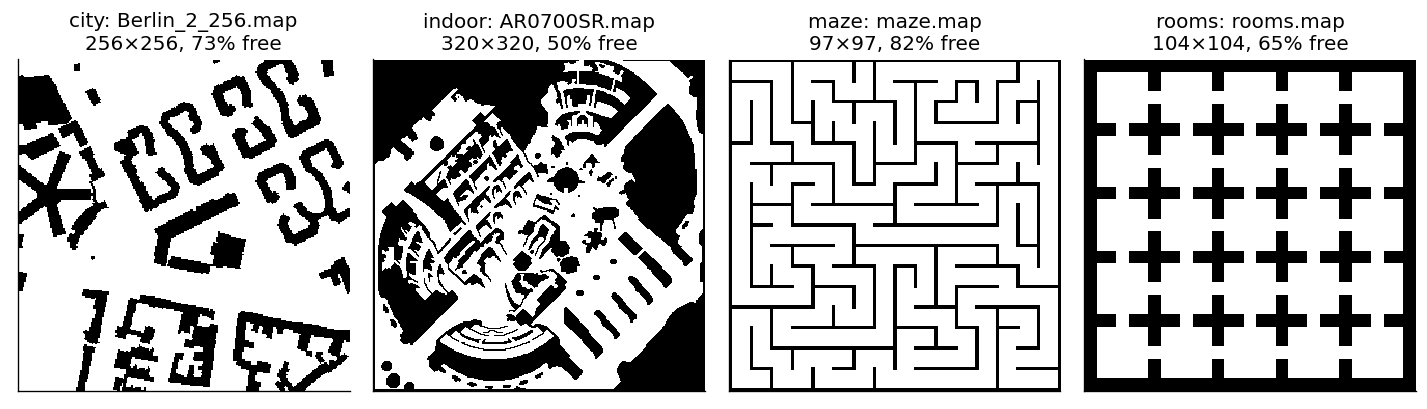

In [2]:
if not BENCH_PATH.exists():
    prepare_benchmark(n_tasks=8)

benchmark = load_benchmark()
maps = load_named_maps(benchmark)
control = build_control_set()
mesh = build_mesh(control)
info = benchmark["control_set"]
print(
    f"{len(benchmark['instances'])} instances, "
    f"{info['primitives']} primitives, {info['configurations']} extended-cell configurations"
)
print(info["description"])

fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))
for ax, row in zip(axes, benchmark["maps"]):
    draw_map(ax, maps[row["file"]], f"{row['topology']}: {row['file']}")
fig.tight_layout()
plt.show()


## Control set

Straight moves and turns share their first cells, which is what lets MeshA* keep them in one bundle and split only when the traces diverge. The arrow is the heading at the start of the bundle.


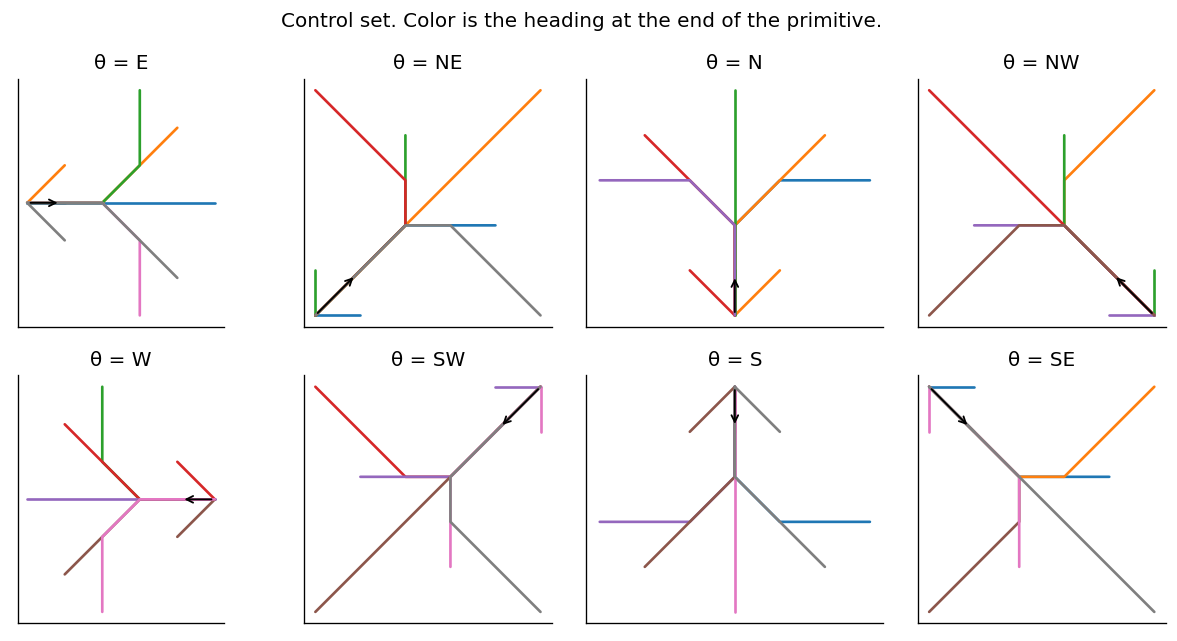

In [3]:
fig = draw_control_set(control)
fig.tight_layout()
plt.show()


## Base solvers

All three searches use `f = g + w h` and do not reopen a closed state. LBA* rejects a primitive before the successor is queued. LazyLBA* queues it and checks the trace at pop time. MeshA* checks the single next cell, and it drops a non-initial bundle once every free endpoint of that bundle has already been expanded.

Weights are `1`, `2`, and `5` on the original query. The two replans are optimal searches (`w = 1`).


In [4]:
records = run_benchmark(benchmark, weights=(1.0, 2.0, 5.0), max_expansions=160_000)
out_path = save_records(records)
print(f"{len(records)} runs -> {out_path}")


[   3/480] Berlin_2_256-00 LBA*=ok:0.069s LazyLBA*=ok:0.046s MeshA*=ok:0.146s


[  18/480] Berlin_2_256-01 LBA*=ok:0.074s LazyLBA*=ok:0.057s MeshA*=ok:0.090s


[  33/480] Berlin_2_256-02 LBA*=ok:0.059s LazyLBA*=ok:0.040s MeshA*=ok:0.067s


[  48/480] Berlin_2_256-03 LBA*=ok:0.008s LazyLBA*=ok:0.007s MeshA*=ok:0.009s


[  63/480] Berlin_2_256-04 LBA*=ok:0.027s LazyLBA*=ok:0.019s MeshA*=ok:0.035s


[  78/480] Berlin_2_256-05 LBA*=ok:0.010s LazyLBA*=ok:0.010s MeshA*=ok:0.011s


... (23 outputs left out)

[ 438/480] rooms-05 LBA*=ok:0.009s LazyLBA*=ok:0.006s MeshA*=ok:0.008s


[ 453/480] rooms-06 LBA*=ok:0.015s LazyLBA*=ok:0.013s MeshA*=ok:0.017s


[ 468/480] rooms-07 LBA*=ok:0.007s LazyLBA*=ok:0.006s MeshA*=ok:0.006s


480 runs -> /home/mperikov/hs/project/results/baseline_runs.json


## Agreement and search cost

At `w = 1` the lattice and the mesh graph are the same optimization problem, so the three solvers should return the same cost whenever they all succeed.


In [5]:
by_key = defaultdict(dict)
for row in records:
    by_key[(row["id"], row["query"], row["weight"])][row["algorithm"]] = row

mismatches = []
for key, algos in by_key.items():
    if key[2] != 1.0:
        continue
    if not all(algos[name]["success"] for name in ALGORITHMS):
        continue
    costs = [algos[name]["cost"] for name in ALGORITHMS]
    if max(costs) - min(costs) > 1e-4:
        mismatches.append((key, costs))
print(f"optimal-cost disagreements: {len(mismatches)}")
if mismatches:
    raise AssertionError(mismatches[:5])

topos = [row["topology"] for row in benchmark["maps"]]
print("w = 1, original query")
print(f"{'topology':<10} {'algorithm':<12} {'solved':>10} {'median exp':>12} {'median cells':>14} {'median s':>10}")
for topo in topos:
    for name in ALGORITHMS:
        rows = [
            row for row in records
            if row["topology"] == topo and row["algorithm"] == name
            and row["weight"] == 1.0 and row["query"] == 0
        ]
        solved = [row for row in rows if row["success"]]
        print(
            f"{topo:<10} {DISPLAY[name]:<12} {len(solved):>4}/{len(rows):<5} "
            f"{median([row['expansions'] for row in solved]):12.0f} "
            f"{median([row['checked_cells'] for row in solved]):14.0f} "
            f"{median([row['elapsed_s'] for row in solved]):10.3f}"
        )


optimal-cost disagreements: 0
w = 1, original query
topology   algorithm        solved   median exp   median cells   median s
city       LBA*            8/8             2792          92924      0.038
city       LazyLBA*        8/8             2790           8315      0.028
city       MeshA*          8/8             6760          18875      0.050
indoor     LBA*            8/8             2784          85625      0.035
indoor     LazyLBA*        8/8             2783          12900      0.030
indoor     MeshA*          8/8             5388          16168      0.037
maze       LBA*            8/8             9182         248964      0.094
maze       LazyLBA*        8/8             9182         113679      0.128
maze       MeshA*          8/8            22082          60540      0.126
rooms      LBA*            8/8              991          30680      0.012
rooms      LazyLBA*        8/8              960           4150      0.008
rooms      MeshA*          8/8             2065           59

## Where the search spends its collision checks

Ratios are per instance, then the median is taken inside each map. The reference is LBA* on that same instance. Checked cells count every grid cell read while testing a primitive (LBA* / LazyLBA*) or a one-cell mesh step (MeshA*).


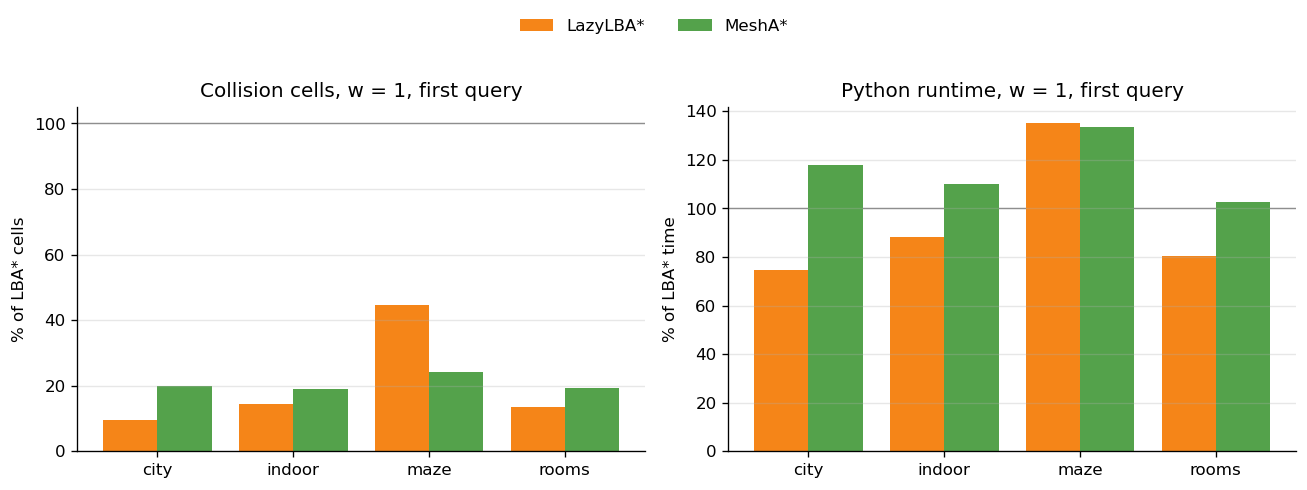

Median collision-cell ratio vs LBA*: LazyLBA* 14%, MeshA* 20%.
Median Python runtime ratio vs LBA*: LazyLBA* 84%, MeshA* 114%.


In [6]:
def paired_ratios(metric, weight=1.0, query=0, baseline="lba"):
    buckets = defaultdict(dict)
    for row in records:
        if row["weight"] != weight or row["query"] != query or not row["success"]:
            continue
        if not row[metric]:
            continue
        buckets[(row["topology"], row["id"])][row["algorithm"]] = row[metric]
    out = defaultdict(lambda: defaultdict(list))
    for (topo, _ident), algos in buckets.items():
        base = algos.get(baseline)
        if not base:
            continue
        for name, value in algos.items():
            if name == baseline:
                continue
            out[topo][name].append(value / base)
    return out


def series_from(ratio_map):
    return {
        name: [100.0 * median(ratio_map[topo][name]) for topo in topos]
        for name in ("lazy_lba", "mesha")
    }


cell_ratios = paired_ratios("checked_cells")
time_ratios = paired_ratios("elapsed_s")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
grouped_bars(
    axes[0], topos, series_from(cell_ratios),
    "% of LBA* cells", "Collision cells, w = 1, first query",
)
grouped_bars(
    axes[1], topos, series_from(time_ratios),
    "% of LBA* time", "Python runtime, w = 1, first query",
)
for ax in axes:
    ax.axhline(100, color="0.5", lw=0.8, zorder=0)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.14))
fig.tight_layout()
plt.show()


def overall(ratio_map, name):
    values = [value for topo in topos for value in ratio_map[topo][name]]
    return 100.0 * median(values)

print(
    f"Median collision-cell ratio vs LBA*: "
    f"LazyLBA* {overall(cell_ratios, 'lazy_lba'):.0f}%, "
    f"MeshA* {overall(cell_ratios, 'mesha'):.0f}%."
)
print(
    f"Median Python runtime ratio vs LBA*: "
    f"LazyLBA* {overall(time_ratios, 'lazy_lba'):.0f}%, "
    f"MeshA* {overall(time_ratios, 'mesha'):.0f}%."
)


## Weight and replanning

The left-hand plots are the cost of a weighted search divided by the optimal LBA* cost on the original map. The right-hand plots are how many states a from-scratch search still expands after each edit. Query 0 is the original task. Query 1 starts closer to the goal, in front of the new obstacle. Query 2 starts in front of the second obstacle. A smaller number there is a shorter remaining problem, not a reused search tree.


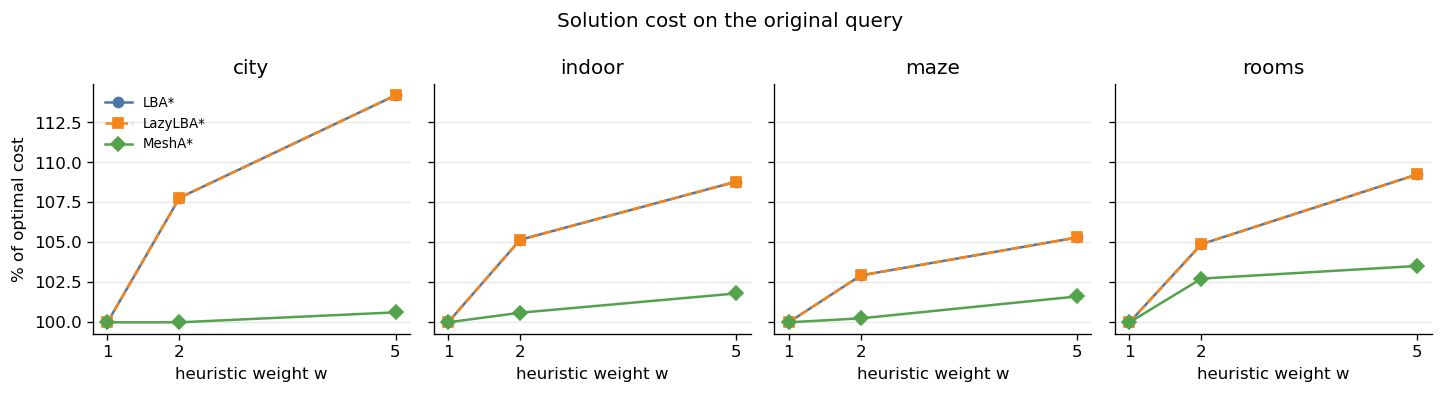

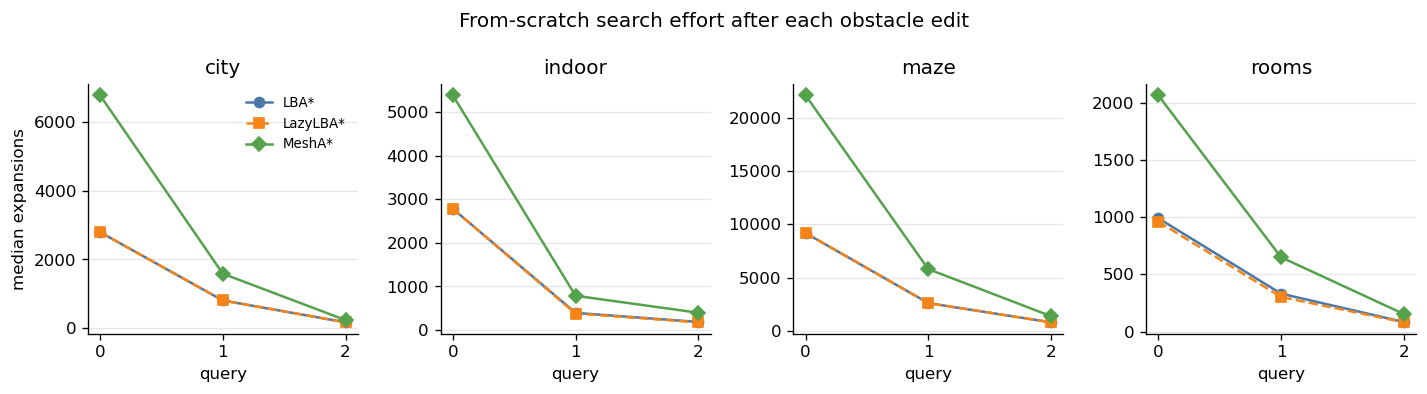

At w = 5, median cost / optimal is city: LBA* 114%, MeshA* 101%, indoor: LBA* 109%, MeshA* 102%, maze: LBA* 105%, MeshA* 102%, rooms: LBA* 109%, MeshA* 104%.
LBA* still expands a median of 442 states on the first replan. OPEN and CLOSED start empty.


In [7]:
def cost_ratio(weight, name, topo):
    optimal = {}
    for row in records:
        if row["query"] == 0 and row["weight"] == 1.0 and row["algorithm"] == "lba" and row["success"]:
            optimal[row["id"]] = row["cost"]
    values = []
    for row in records:
        if row["topology"] != topo or row["query"] != 0 or row["weight"] != weight:
            continue
        if row["algorithm"] != name or not row["success"]:
            continue
        base = optimal.get(row["id"])
        if base:
            values.append(row["cost"] / base)
    return median(values)


weights = (1.0, 2.0, 5.0)
styles = {"lba": ("-", "o"), "lazy_lba": ("--", "s"), "mesha": ("-", "D")}
fig, axes = plt.subplots(1, 4, figsize=(12, 3.3), sharey=True)
for ax, topo in zip(axes, topos):
    for name in ALGORITHMS:
        ys = [100.0 * cost_ratio(weight, name, topo) for weight in weights]
        linestyle, marker = styles[name]
        ax.plot(weights, ys, linestyle=linestyle, marker=marker, color=COLORS[name], label=DISPLAY[name])
    ax.set_title(topo)
    ax.set_xlabel("heuristic weight w")
    ax.set_xticks(weights)
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("% of optimal cost")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("Solution cost on the original query")
fig.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 4, figsize=(12, 3.3), sharey=False)
for ax, topo in zip(axes, topos):
    for name in ALGORITHMS:
        ys = []
        for query in (0, 1, 2):
            rows = [
                row["expansions"]
                for row in records
                if row["topology"] == topo
                and row["algorithm"] == name
                and row["weight"] == 1.0
                and row["query"] == query
                and row["success"]
            ]
            ys.append(median(rows))
        linestyle, marker = styles[name]
        ax.plot([0, 1, 2], ys, linestyle=linestyle, marker=marker, color=COLORS[name], label=DISPLAY[name])
    ax.set_title(topo)
    ax.set_xlabel("query")
    ax.set_xticks([0, 1, 2])
    ax.grid(axis="y", alpha=0.3)
axes[0].set_ylabel("median expansions")
axes[0].legend(frameon=False, fontsize=8)
fig.suptitle("From-scratch search effort after each obstacle edit")
fig.tight_layout()
plt.show()

mesh_w5 = [
    cost_ratio(5.0, "mesha", topo) for topo in topos
]
lba_w5 = [
    cost_ratio(5.0, "lba", topo) for topo in topos
]
print(
    "At w = 5, median cost / optimal is "
    + ", ".join(
        f"{topo}: LBA* {100 * lba_pct:.0f}%, MeshA* {100 * mesh_pct:.0f}%"
        for topo, lba_pct, mesh_pct in zip(topos, lba_w5, mesh_w5)
    )
    + "."
)
q1 = [
    row["expansions"]
    for row in records
    if row["algorithm"] == "lba" and row["weight"] == 1.0 and row["query"] == 1 and row["success"]
]
print(
    f"LBA* still expands a median of {median(q1):.0f} states on the first replan. "
    "OPEN and CLOSED start empty."
)


## Solutions

Blue squares are cells the search expanded. The red polyline is the primitive path. Green is the start heading, blue is the goal heading, and orange is a cell that was free in the base map and is blocked in this query. The window is the path, the expanded cells, and the edits, with a small margin.

The first gallery is MeshA* at `w = 1`, before the edit and after the first edit. The second gallery is the median-cost city task under all three base solvers, plus MeshA* at `w = 5`.


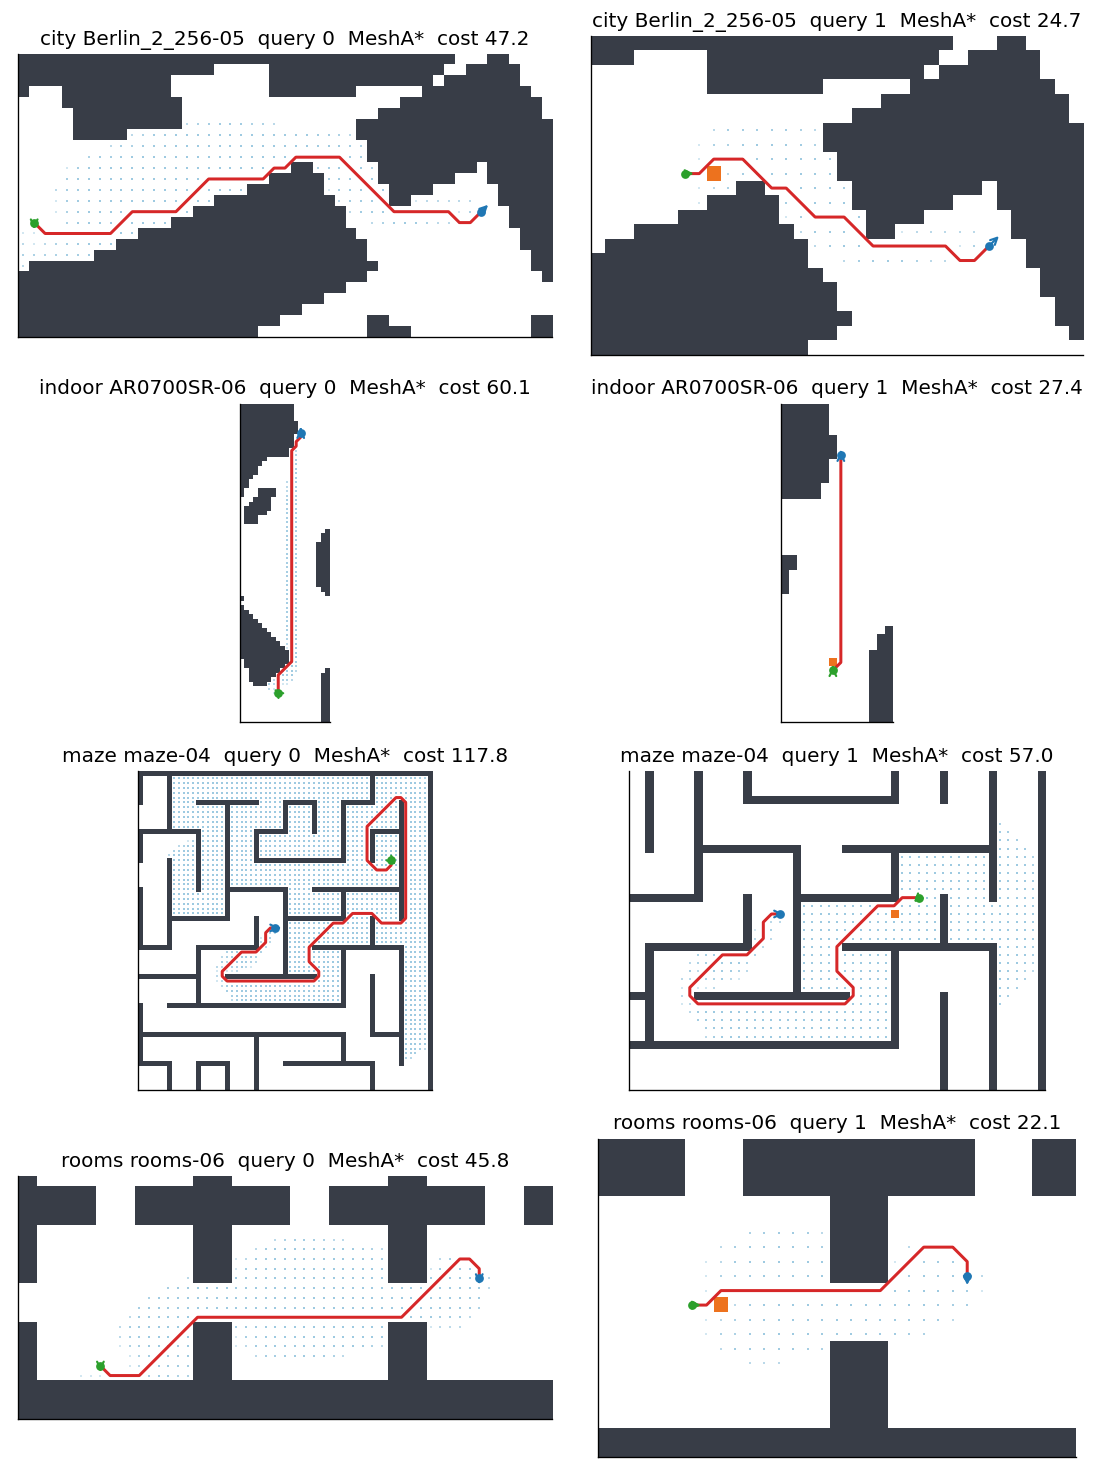

In [8]:
def median_instance(topology):
    group = [item for item in benchmark["instances"] if item["topology"] == topology]
    group.sort(key=lambda item: item["reference_cost"])
    return group[len(group) // 2]


def solve_query(instance, query_index, algorithm, weight=1.0):
    query = instance["queries"][query_index]
    grid = apply_blocks(maps[instance["map"]], query["blocks"])
    result = search(
        algorithm,
        grid,
        control,
        tuple(query["start"]),
        tuple(query["goal"]),
        mesh,
        weight=weight,
        max_expansions=160_000,
        return_path=True,
    )
    return query, result


chosen = [median_instance(topo) for topo in topos]
fig, axes = plt.subplots(len(chosen), 2, figsize=(9.4, 3.1 * len(chosen)))
for row, instance in enumerate(chosen):
    for col, query_index in enumerate((0, 1)):
        query, result = solve_query(instance, query_index, "mesha")
        cost = f"{result.cost:.1f}" if result.success else "fail"
        draw_solution(
            axes[row, col],
            maps[instance["map"]],
            query["blocks"],
            query["start"],
            query["goal"],
            result.trace,
            result.expanded,
            f"{instance['topology']} {instance['id']}  query {query_index}  MeshA*  cost {cost}",
        )
fig.tight_layout()
plt.show()


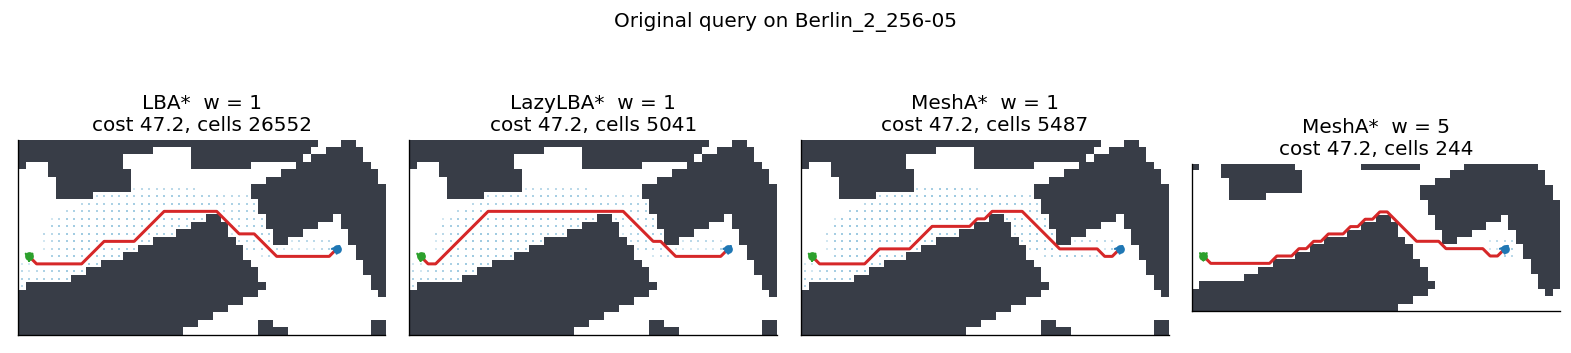

In [9]:
city = median_instance("city")
panels = (
    ("lba", 1.0, "LBA*  w = 1"),
    ("lazy_lba", 1.0, "LazyLBA*  w = 1"),
    ("mesha", 1.0, "MeshA*  w = 1"),
    ("mesha", 5.0, "MeshA*  w = 5"),
)
fig, axes = plt.subplots(1, 4, figsize=(13.2, 3.6))
for ax, (algorithm, weight, label) in zip(axes, panels):
    query, result = solve_query(city, 0, algorithm, weight)
    cost = f"{result.cost:.1f}" if result.success else "fail"
    cells = 0 if not result.checked_cells else result.checked_cells
    draw_solution(
        ax,
        maps[city["map"]],
        query["blocks"],
        query["start"],
        query["goal"],
        result.trace,
        result.expanded,
        f"{label}\ncost {cost}, cells {cells}",
    )
fig.suptitle(f"Original query on {city['id']}")
fig.tight_layout()
plt.show()


## Reading the runs

MeshA* walks a primitive one cell at a time and drops a bundle once every free endpoint has been expanded. On the original query it checks about a fifth as many collision cells as LBA*. LazyLBA* checks fewer still: a trace is read only when that successor is popped, so primitives that lose the g-value race never touch the grid.

In this Python implementation MeshA* is slower than LBA* by about 14% on the median of the original queries. Every cell of a primitive is its own queue node, and that traffic uses more interpreter time than the cell saving wins back. The cell counts are the comparison that stays meaningful across languages. The paper's C++ planner turns the same saving into a 1.5×–2× wall-time improvement.

LBA* and LazyLBA* return the same costs in this sweep; lazy collision checking changes which traces are read, and the valid edges keep their costs. At `w = 5` those lattice paths rise to about 105–114% of optimal. MeshA* stays within about 104%. A large weight multiplies the still-unpaid primitive length on every intermediate mesh cell, so a half-finished long arc looks expensive and the search keeps the short steps. Those short steps have the same length as the long straights. LBA* scores a primitive only at its endpoint, and a large weight will take a longer greedy arc. On the paper's smoother car primitives the tilt went the other way: weighted MeshA* became the more suboptimal of the two. The curves above are this 8×8 control set.

Every replan starts with an empty open list. After the first edit LBA* still expands a few hundred states, following the length of the suffix that remains. These three solvers are the from-scratch baseline for an incremental MeshA* that would keep the mesh-graph labels from one edit to the next.
